In [1]:
import xarray as xr 
import numpy as np
from glob import glob
from pathlib import Path

from scipy.optimize import curve_fit

import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.pyplot as plt
import matplotlib.colors as colors

from cmcrameri import cm as cmcra
import plotting_utils

In [2]:
# importing processed dataset
path_source = Path('../steady_out/') #don't forget the final '/'
exp =  'TEMP'
ds = xr.open_dataset(path_source / (exp + '.nc'))

# Scaling for basal melt rate as a function of $T_0$

In [3]:
def plot_scatter(ax, size=30):
    """Plot forward and backward experiments."""

    for j in range(melt_wtc.shape[1]):
        ax.scatter(
            thermal_driving, melt_wtc[:, j],
            color=colors[j], **scatter_kwargs(size)
        )

        if j != idx_cold:
            ax.scatter(
            thermal_driving, melt_ctw[:, j],
                color=colors[j], **scatter_kwargs(size)
            )

    # Plot cold-mode points last (so they appear on top of other points)
    ax.scatter(
        thermal_driving, melt_ctw[:, idx_cold],
        color=colors[idx_cold], **scatter_kwargs(size)
    )


def scatter_kwargs(size):
    return dict(
        s=size, edgecolors="black",
        linewidths=0.3, alpha=0.7, zorder=2
    )


def fit_power_law(x, y, exponent=None):
    """
    Fit y = a*x**n.

    exponent=None: fit both a and n in log-log space.
    exponent=n: fit only a, keeping n fixed.
    """
    mask = np.isfinite(x) & np.isfinite(y) & (x > 0)

    if exponent is None:
        mask &= y > 0

    x, y = x[mask], y[mask]

    if exponent is None:
        n, log_a = np.polyfit(np.log(x), np.log(y), 1)
        a = np.exp(log_a)
    else:
        popt, _ = curve_fit(
            lambda x, a: a * x**exponent, x, y
        )
        a, n = popt[0], exponent

    return a, n

linear - Warm: a = 2.130, n = 2.000
linear - Cold: a = 0.886, n = 1.000


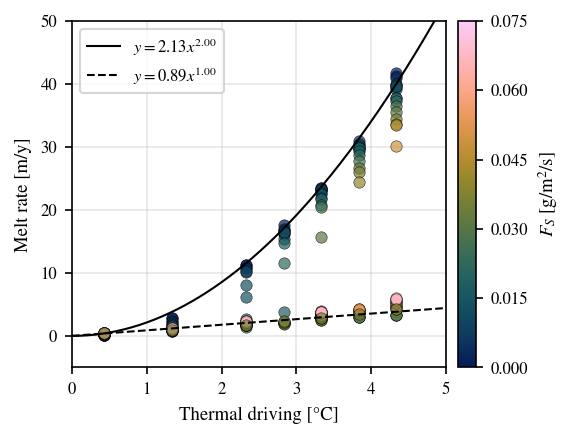

log - Warm: a = 1.281, n = 2.424
log - Cold: a = 0.810, n = 1.037


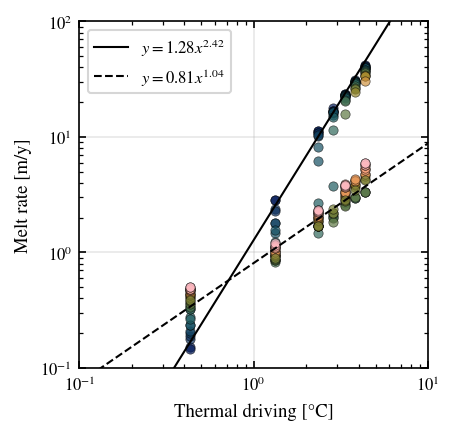

In [4]:
T0_max = ds.T0.values
thermal_driving = T0_max - (-2.33186)

idx_warm = 0
idx_cold = 8

colors = cmcra.batlow(np.linspace(0, 0.9, 16))

melt_wtc = ds.melt_0D.sel(transition="wtc").values[:,:16]
melt_ctw = ds.melt_0D.sel(transition="ctw").values[:,:16]

# Curves to fit: (data, fixed exponent, linestyle, label)
fit_data = [
    (melt_wtc[:, idx_warm], 2, "-", "Warm"),
    (melt_ctw[:, idx_cold], 1, "--", "Cold"),
]



### Plotting

fig_configs = [
    ("linear", (3.5, 3), 30, "melt_lin.pdf"),
    ("log", (3, 3), 20, "melt_log.pdf"),
]

for scale, figsize, marker_size, filename in fig_configs:

    fig, ax = plt.subplots(figsize=figsize, dpi=150)

    plot_scatter(ax, size=marker_size)

    # Fit and plot power laws
    x_fit = (
        np.linspace(0, 5, 200) if scale == "linear"
        else np.geomspace(0.1, 10, 200)
    )

    for y, fixed_n, linestyle, name in fit_data:

        a, n = fit_power_law(
            thermal_driving, y,
            exponent=fixed_n if scale == "linear" else None
        )

        print(f"{scale} - {name}: a = {a:.3f}, n = {n:.3f}")

        ax.plot(
            x_fit, a * x_fit**n,
            linestyle=linestyle, color="black",
            lw=1, zorder=3,
            label=fr"$y={a:.2f}x^{{{n:.2f}}}$"
        )


    # Axes
    ax.set_xlabel("Thermal driving [°C]")
    ax.set_ylabel("Melt rate [m/y]")

    if scale == "linear":
        ax.set_xlim(0, 5)
        ax.set_ylim(-5, 50)

        # colorbar
        sm = plt.cm.ScalarMappable(
            cmap=cmcra.batlow,
            norm=plt.Normalize(vmin=0, vmax=0.075)
        )
        sm.set_array([])

        cbar = fig.colorbar(
            sm, ax=ax,
            pad=0.03,
            fraction=0.05
        )
        cbar.set_label(r"$F_S$ [g/m$^2$/s]")
        cbar.set_ticks(np.arange(0, 0.076, 0.015))

    elif scale == "log":
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(0.1, 10)
        ax.set_ylim(0.1, 100)
        ax.tick_params(which="both", direction="in", top=True, right=True)

    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    


    fig.savefig('./Figure6/' + filename, format="pdf", bbox_inches="tight")
    plt.show()


# Scaling melt deep-upper cavity

In [5]:
rho_i = 910 #kg/m3
dx = 2000 #m
dy = 2000 #m

deep_melt_wtc = ds.melt_2D.sel(T0=1, transition="wtc").isel(x_T=slice(0,25)).sum(dim=["x_T","y_T"]).values[:16] * dx * dy *910 / 1e12
deep_melt_ctw = ds.melt_2D.sel(T0=1, transition="ctw").isel(x_T=slice(0,25)).sum(dim=["x_T","y_T"]).values[:16] * dx * dy * 910 / 1e12

front_melt_wtc = ds.melt_2D.sel(T0=1, transition="wtc").isel(x_T=slice(25,50)).sum(dim=["x_T","y_T"]).values[:16] * dx * dy * 910 / 1e12
front_melt_ctw = ds.melt_2D.sel(T0=1, transition="ctw").isel(x_T=slice(25,50)).sum(dim=["x_T","y_T"]).values[:16] * dx * dy * 910 / 1e12

sfx_list = np.arange(0,0.075+0.001,0.005)

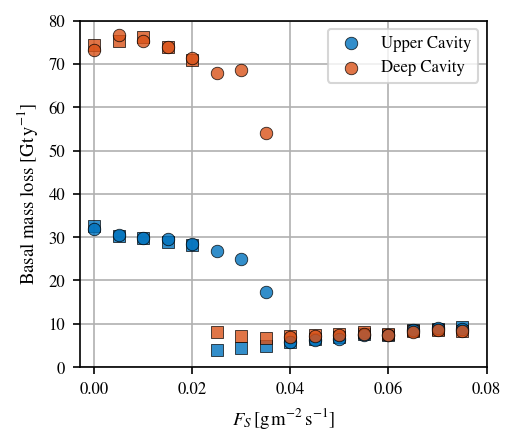

In [6]:
blue = '#0072bd'
red = '#d95319'

plt.figure(figsize=(3.5,3),dpi=150)

plt.scatter(sfx_list, front_melt_ctw, zorder=2, marker='s',facecolors=blue, edgecolors='black', linewidth=0.4, alpha=0.8)
plt.scatter(sfx_list, deep_melt_ctw, zorder=2, marker='s',facecolors=red,edgecolors='black', linewidth=0.4, alpha=0.8)

plt.scatter(sfx_list, front_melt_wtc, zorder=2, label='Upper Cavity', marker='o', facecolors=blue,edgecolors='black', linewidth=0.4, alpha=0.8)
plt.scatter(sfx_list, deep_melt_wtc, zorder=2, label='Deep Cavity', marker='o', facecolors=red,edgecolors='black', linewidth=0.4, alpha=0.8)


plt.grid()

plt.legend(loc='upper right')

plt.xlabel(r"$F_S \, \mathrm{[g \, m^{-2} \, s^{-1}]}$")
plt.ylabel(r"Basal mass loss [$\mathrm{Gt\,y^{-1}}$]")

plt.ylim(0,80)
plt.xlim(-0.003,0.08)

plt.savefig('./Figure7/deep_upper.pdf', format='pdf', bbox_inches='tight')


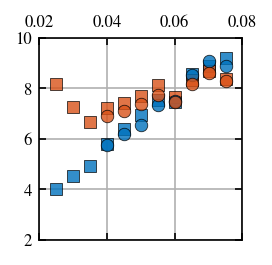

In [7]:
plt.figure(figsize=(1.75,1.75),dpi=150)

plt.scatter(sfx_list, front_melt_ctw, zorder=2, marker='s',facecolors=blue, edgecolors='black', linewidth=0.4, alpha=0.8)
plt.scatter(sfx_list, deep_melt_ctw, zorder=2, marker='s',facecolors=red,edgecolors='black', linewidth=0.4, alpha=0.8)

plt.scatter(sfx_list, front_melt_wtc, zorder=2, label='Upper Cavity', marker='o', facecolors=blue,edgecolors='black', linewidth=0.4, alpha=0.8)
plt.scatter(sfx_list, deep_melt_wtc, zorder=2, label='Deep Cavity', marker='o', facecolors=red,edgecolors='black', linewidth=0.4, alpha=0.8)


plt.grid()

# plt.xlabel(r"$F_S \, \mathrm{[g \, m^{-2} \, s^{-1}]}$")
# plt.ylabel(r"Basal mass loss [$\mathrm{Gt\,y^{-1}}$]")

ax = plt.gca()
ax.tick_params(which='both', direction='in', top=True, right=True, labeltop=True, labelbottom=False)

plt.ylim(2,10)
plt.xlim(0.02,0.08)

plt.savefig('./Figure7/deep_upper_inset.pdf', format='pdf', bbox_inches='tight')

# Scaling transition thresholds

In [8]:
# make list non dimensional 

Fs_list = np.arange(0, 0.075+0.001, 0.005)

T0_list = [2, 1.5, 1, 0.5, 0] # °C

# second to last indexes before each transition
list_idx_wtc = [10,8,6,4,2]
list_idx_ctw = np.array([6,6,6,5,5])

tab_melt_adim_wtc = []
tab_melt_adim_ctw = []

tab_sfx_adim = []

for index in range(5):

    fs_melt_wtc_arr = ds.Sb_qfw.sel(T0=T0_list[index], transition="wtc").values[:16]
    fs_melt_ctw_arr = ds.Sb_qfw.sel(T0=T0_list[index], transition="ctw").values[:16]

    qfw_wtc_arr = ds.qfw.sel(T0=T0_list[index], transition="wtc").values[:16]
    qfw_ctw_arr = ds.qfw.sel(T0=T0_list[index], transition="ctw").values[:16]

    #  factor 5 because ice shelf 5 time larger than the polynya
    sfx_ctw = fs_melt_ctw_arr[list_idx_ctw[index]] * 5
    sfx_wtc = fs_melt_wtc_arr[list_idx_wtc[index]] * 5

    # taking into account heat effects
    alpha = 3.733e-5 # /°C
    beta = 7.843e-4 #/psu
    LatentHeat = 3.34e5 #J/kg
    cp = 3974 #J/kg/K
    sfx_ctw -= alpha/beta * 5 * LatentHeat/cp * qfw_ctw_arr[list_idx_ctw[index]] 
    sfx_wtc -= alpha/beta * 5 * LatentHeat/cp * qfw_wtc_arr[list_idx_wtc[index]] 

    fs = (Fs_list-sfx_ctw)/(sfx_wtc-sfx_ctw)

    m_adim_wtc = (qfw_wtc_arr-qfw_ctw_arr[list_idx_ctw[index]])/(qfw_wtc_arr[list_idx_wtc[index]]-qfw_ctw_arr[list_idx_ctw[index]])
    m_adim_ctw = (qfw_ctw_arr-qfw_ctw_arr[list_idx_ctw[index]])/(qfw_wtc_arr[list_idx_wtc[index]]-qfw_ctw_arr[list_idx_ctw[index]])


    tab_melt_adim_wtc.append(m_adim_wtc)
    tab_melt_adim_ctw.append(m_adim_ctw)

    tab_sfx_adim.append(fs)


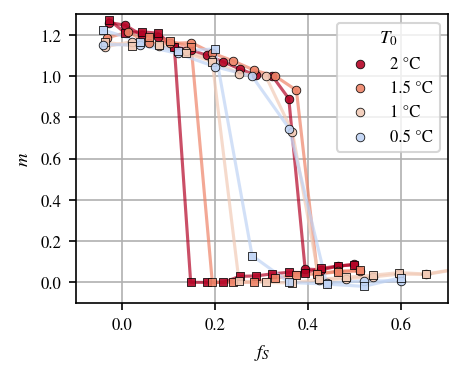

In [9]:
colors_plot =  [cm.coolwarm(x) for x in np.linspace(1, 0, 6)]+[cmcra.lipari(0.05)]

labels = ['2 °C', '1.5 °C', '1 °C', '0.5 °C', '0 °C']


plt.figure(figsize=(3.2,2.5),dpi=150)

for index in range(4):

    plt.plot(tab_sfx_adim[index],tab_melt_adim_wtc[index], color=colors_plot[index], alpha=0.7,)
    plt.plot(tab_sfx_adim[index],tab_melt_adim_ctw[index], color=colors_plot[index], alpha=0.7,)


for index in range(4):
    plt.scatter(tab_sfx_adim[index],tab_melt_adim_wtc[index], marker='o', edgecolors='black', facecolors=colors_plot[index], lw=0.4, s=17, alpha=0.9,zorder=2, label=labels[index])
    plt.scatter(tab_sfx_adim[index],tab_melt_adim_ctw[index], marker='s', edgecolors='black', facecolors=colors_plot[index], lw=0.4, s=17, alpha=0.9,zorder=2)

plt.xlabel(r'$f_S$') 
plt.ylabel(r'$m$')


plt.xlim(-0.1,0.7)
plt.ylim(-0.1, 1.3)

#plt.yscale('log')

plt.grid()

plt.legend(title=r'$T_0$',title_fontsize=9)

plt.savefig('./Figure8/scaling_thresholds.pdf', format='pdf', bbox_inches='tight')

plt.show()